In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

data_path = Path("data") / "detect_dataset.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset shape: (12001, 7)
Column names: ['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']


,Output (S),Ia,Ib,Ic,Va,Vb,Vc
0,0,-170.472196,9.219613,161.252583,0.054490,-0.659921,0.605431
1,0,-122.235754,6.168667,116.067087,0.102000,-0.628612,0.526202
2,0,-90.161474,3.813632,86.347841,0.141026,-0.605277,0.464251
3,0,-79.904916,2.398803,77.506112,0.156272,-0.602235,0.445963
4,0,-63.885255,0.590667,63.294587,0.180451,-0.591501,0.411050


In [2]:
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Data types:
Output (S)      int64
Ia            float64
Ib            float64
Ic            float64
Va            float64
Vb            float64
Vc            float64
dtype: object

Missing values:
Output (S)    0
Ia            0
Ib            0
Ic            0
Va            0
Vb            0
Vc            0
dtype: int64


In [3]:
# Rename the target column
df = df.rename(columns={"Output (S)": "fault"})

# Display the updated column names
print("Updated columns:", df.columns.tolist())

# Count fault and no-fault observations
print("\nClass counts:")
print(df["fault"].value_counts().sort_index())

Updated columns: ['fault', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

Class counts:
fault
0    6505
1    5496
Name: count, dtype: int64


In [4]:
rng = np.random.default_rng(42)

idx = rng.permutation(len(df))

n_train = int(0.6 * len(df))
n_val = int(0.2 * len(df))

train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Testing rows:", len(test_idx))

Training rows: 7200
Validation rows: 2400
Testing rows: 2401


In [6]:

# Separate the rows into training,validation and test set
train_df = df.iloc[train_idx]
val_df = df.iloc[val_idx]
test_df = df.iloc[test_idx]

# **Calculate the fraction of observations labelled as faults**
print("Training fault fraction:", train_df["fault"].mean())
print("Validation fault fraction:", val_df["fault"].mean())
print("Testing fault fraction:", test_df["fault"].mean())

NameError: name 'df' is not defined

In [6]:

# Select six input features
features = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]

X_train = train_df[features].to_numpy()
X_val = val_df[features].to_numpy()
X_test = test_df[features].to_numpy()

# **Calculate mean and standard deviation using training data only**
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

# **Standardize all three sets using the training statistics**
X_train_scaled = (X_train - train_mean) / train_std
X_val_scaled = (X_val - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std

# **Check the standardized training data**
print("Training feature means:", X_train_scaled.mean(axis=0))
print("Training feature standard deviations:", X_train_scaled.std(axis=0))
print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training feature means: [-1.57898386e-17  1.13489465e-17  1.77635684e-17  9.86864911e-18
 -1.48029737e-17 -3.57738530e-17]
Training feature standard deviations: [1. 1. 1. 1. 1. 1.]
Training data shape: (7200, 6)
Validation data shape: (2400, 6)
Testing data shape: (2401, 6)


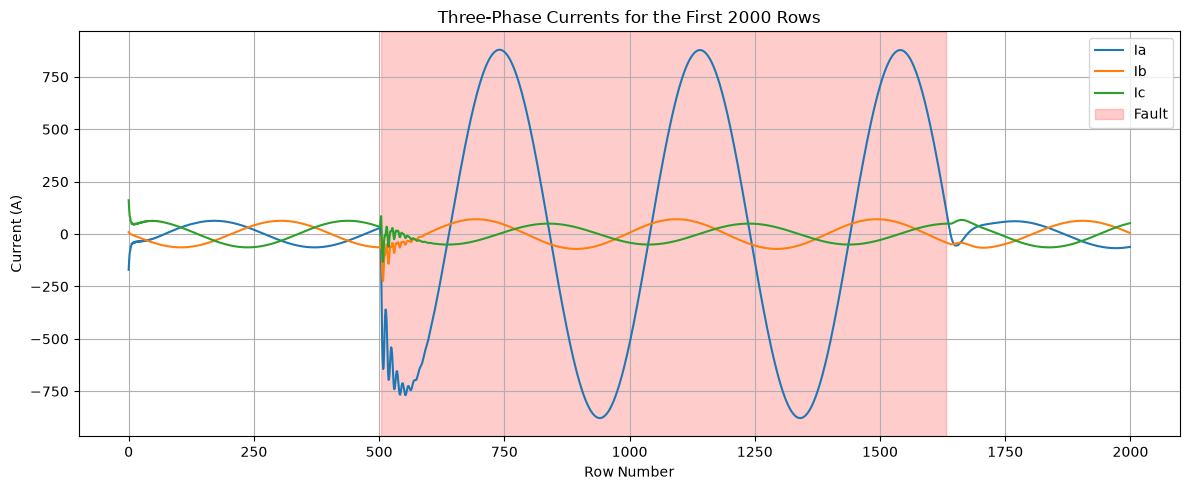

In [8]:
import matplotlib.pyplot as plt

# Plot the three phase currents for the first 2000 rows
plot_df = df.iloc[:2000]

plt.figure(figsize=(12, 5))

plt.plot(plot_df.index, plot_df["Ia"], label="Ia")
plt.plot(plot_df.index, plot_df["Ib"], label="Ib")
plt.plot(plot_df.index, plot_df["Ic"], label="Ic")

# **Shade the background wherever a fault is present**
fault_rows = plot_df["fault"].to_numpy()

plt.fill_between(
    plot_df.index,
    0, 1,
    where=fault_rows == 1,
    transform=plt.gca().get_xaxis_transform(),
    alpha=0.2,
    color="red",
    label="Fault"
)

plt.xlabel("Row Number")
plt.ylabel("Current (A)")
plt.title("Three-Phase Currents for the First 2000 Rows")
plt.legend()
plt.grid(True)
plt.tight_layout()
# **Save the graph in the results folder**
from pathlib import Path

Path("results").mkdir(exist_ok=True)
plt.savefig("results/plot1_currents.png", dpi=300, bbox_inches="tight")

plt.show()
plt.show()

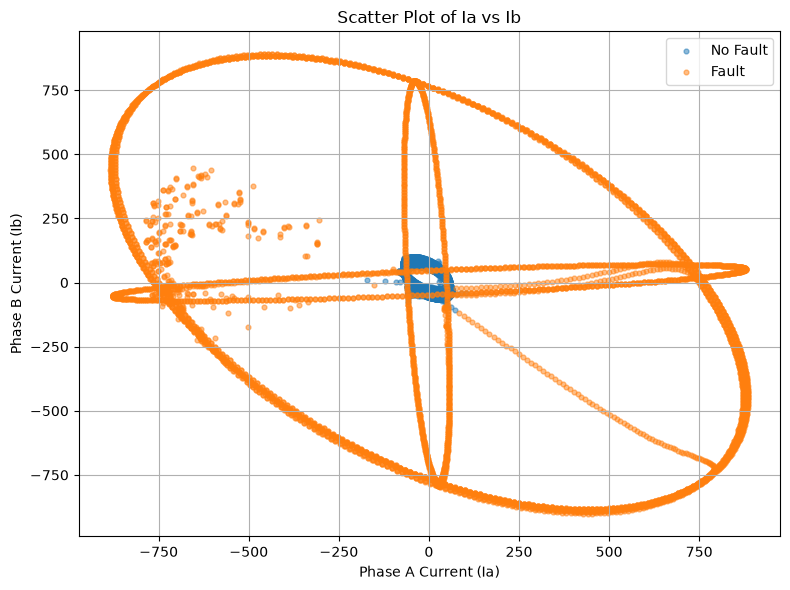

In [11]:
# Scatter plot of Ia against Ib

plt.figure(figsize=(8, 6))

for label, name in [(0, "No Fault"), (1, "Fault")]:
    subset = df[df["fault"] == label]
    plt.scatter(
        subset["Ia"],
        subset["Ib"],
        label=name,
        alpha=0.5,
        s=12
    )


plt.xlabel("Phase A Current (Ia)")
plt.ylabel("Phase B Current (Ib)")
plt.title("Scatter Plot of Ia vs Ib")
plt.legend()
plt.grid(True)
plt.tight_layout()

# **Save the plot for the report**
Path("results").mkdir(exist_ok=True)
plt.savefig("results/plot2_ia_vs_ib.png", dpi=300, bbox_inches="tight")

plt.show()

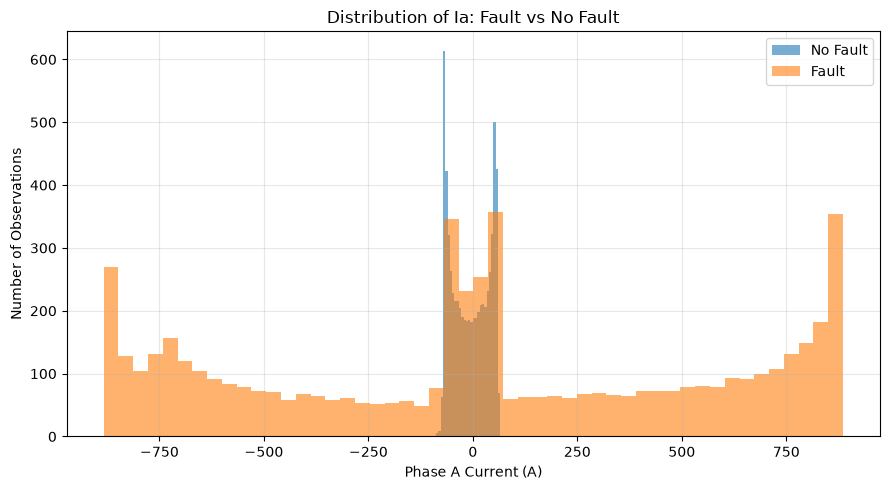

In [12]:
# Compare phase A current for fault and no-fault observations

plt.figure(figsize=(9, 5))

no_fault = df[df["fault"] == 0]["Ia"]
fault = df[df["fault"] == 1]["Ia"]

plt.hist(no_fault, bins=50, alpha=0.6, label="No Fault")
plt.hist(fault, bins=50, alpha=0.6, label="Fault")

plt.xlabel("Phase A Current (A)")
plt.ylabel("Number of Observations")
plt.title("Distribution of Ia: Fault vs No Fault")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

Path("results").mkdir(exist_ok=True)
plt.savefig("results/plot3_ia_histogram.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# Define the sigmoid function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("Sigmoid of -3:", sigmoid(-3))
print("Sigmoid of 0:", sigmoid(0))
print("Sigmoid of 3:", sigmoid(3))

Sigmoid of -3: 0.04742587317756678
Sigmoid of 0: 0.5
Sigmoid of 3: 0.9525741268224334


In [ ]:
#hypothesisfunction

def hypothesis(X, theta):
    return sigmoid(X @ theta)

In [16]:
# Add an intercept column to each dataset split

X_train_lr = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_val_lr = np.c_[np.ones(X_val_scaled.shape[0]), X_val_scaled]
X_test_lr = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]

# **Separate the target labels**
y_train = train_df["fault"].to_numpy()
y_val = val_df["fault"].to_numpy()
y_test = test_df["fault"].to_numpy()

# **Check the new shapes**
print("Training matrix:", X_train_lr.shape)
print("Validation matrix:", X_val_lr.shape)
print("Testing matrix:", X_test_lr.shape)

Training matrix: (7200, 7)
Validation matrix: (2400, 7)
Testing matrix: (2401, 7)


In [ ]:
#test hypthesis function

theta = np.zeros(X_train_lr.shape[1])

# **Calculate fault probabilities**
probabilities = hypothesis(X_train_lr, theta)

# **Display the first five probabilities**
print("First five probabilities:", probabilities[:5])

First five probabilities: [0.5 0.5 0.5 0.5 0.5]


In [ ]:
# costfunction

def cost(X, y, theta):
    h = hypothesis(X, theta)

    #Prevent log of 0
    h = np.clip(h, 1e-12, 1 - 1e-12)

    #average logistic loss
    J = -np.mean(y * np.log(h) + (1 - y) * np.log(1 - h))

    return J



In [20]:
# **Test the cost with zero weights**
print("Initial cost:", cost(X_train_lr, y_train, theta))

Initial cost: 0.6931471805599452


In [ ]:
# Train Logistic Regression using batch gradient descent

def fit_logistic(X, y, alpha, n_iters):

    #Start all weights at zero
    theta = np.zeros(X.shape[1])

    costs = []

    # Update weights repeatedly
    for i in range(n_iters):
        h = hypothesis(X, theta)
        error = y - h

        #Calculate the gradient and update the weights
        gradient = (X.T @ error) / len(y)
        theta = theta + alpha * gradient

        #Record the updated cost
        costs.append(cost(X, y, theta))

    return theta, costs

In [22]:
# **Test gradient descent for 10 iterations**

theta_test, costs_test = fit_logistic(
    X_train_lr, y_train, alpha=0.01, n_iters=10
)

print("Initial cost:", 0.6931471805599452)
print("Cost after 10 iterations:", costs_test[-1])
print("First three learned weights:", theta_test[:3])

Initial cost: 0.6931471805599452
Cost after 10 iterations: 0.6920821962539265
First three learned weights: [-0.00388663  0.00173781 -0.00671221]


In [23]:
# Compare different learning rates

learning_rates = [0.01, 0.1, 1, 10]
cost_histories = {}

# Train a model using each learning rate
for alpha in learning_rates:
    theta, costs = fit_logistic(
        X_train_lr, y_train, alpha, 2000
    )
    cost_histories[alpha] = costs

    print(f"Learning rate: {alpha}")
    print(f"Final cost: {costs[-1]:.6f}")
    print(f"Cost always decreases: {all(costs[i] < costs[i-1] for i in range(1, len(costs)))}")
    print()

Learning rate: 0.01
Final cost: 0.677195
Cost always decreases: True

Learning rate: 0.1
Final cost: 0.677161
Cost always decreases: True

Learning rate: 1
Final cost: 0.677161
Cost always decreases: True

Learning rate: 10
Final cost: 1.343940
Cost always decreases: False



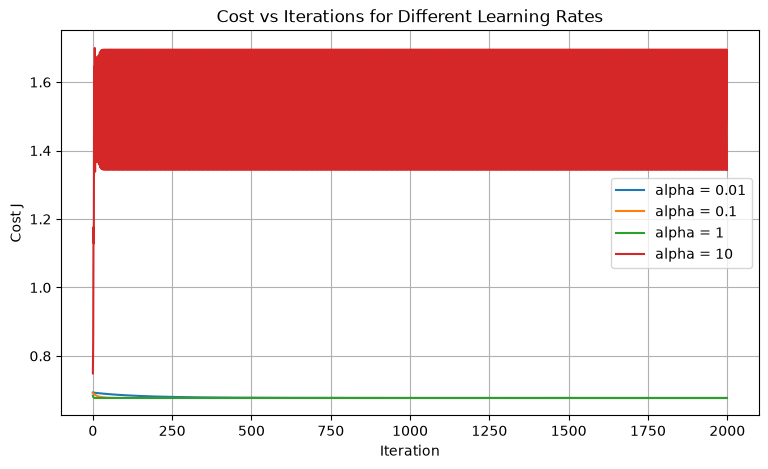

In [24]:
# Plot cost for different learning rates

plt.figure(figsize=(9, 5))

for alpha in learning_rates:
    plt.plot(cost_histories[alpha], label=f"alpha = {alpha}")

plt.xlabel("Iteration")
plt.ylabel("Cost J")
plt.title("Cost vs Iterations for Different Learning Rates")
plt.legend()
plt.grid(True)

Path("results").mkdir(exist_ok=True)
plt.savefig("results/learning_rate_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

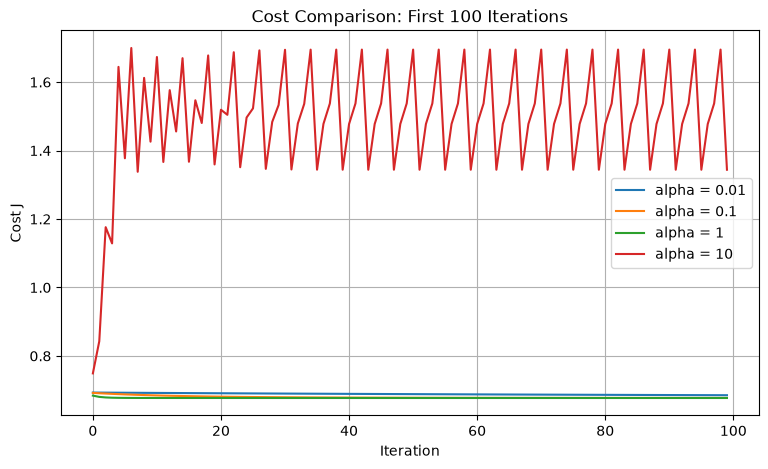

In [25]:
# Zoom in on the first 100 iterations

plt.figure(figsize=(9, 5))

for alpha in learning_rates:
    plt.plot(cost_histories[alpha][:100], label=f"alpha = {alpha}")

plt.xlabel("Iteration")
plt.ylabel("Cost J")
plt.title("Cost Comparison: First 100 Iterations")
plt.legend()
plt.grid(True)

plt.savefig("results/learning_rate_comparison_zoom.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [5]:

#Create Set Q with squared features

# Get the og, unstandardized features
X_train_raw = train_df[features].to_numpy()
X_val_raw = val_df[features].to_numpy()
X_test_raw = test_df[features].to_numpy()

# Add square of each feature
X_train_q = np.c_[X_train_raw, X_train_raw ** 2]
X_val_q = np.c_[X_val_raw, X_val_raw ** 2]
X_test_q = np.c_[X_test_raw, X_test_raw ** 2]

# Check number of feature
print("Set R features:", X_train_raw.shape[1])
print("Set Q features:", X_train_q.shape[1])
print("Training shape:", X_train_q.shape)
print("Validation shape:", X_val_q.shape)
print("Testing shape:", X_test_q.shape)


NameError: name 'train_df' is not defined

In [ ]:

#  Standardize Set Q using training statistics

# Calculate statistics from training data only
q_mean = X_train_q.mean(axis=0)
q_std = X_train_q.std(axis=0)

# Standardize all three sets using training statistics
X_train_q_scaled = (X_train_q - q_mean) / q_std
X_val_q_scaled = (X_val_q - q_mean) / q_std
X_test_q_scaled = (X_test_q - q_mean) / q_std

# Check the results
print("Training means:", np.round(X_train_q_scaled.mean(axis=0), 4))
print("Training standard deviations:",
      np.round(X_train_q_scaled.std(axis=0), 4))

print("Training shape:", X_train_q_scaled.shape)
print("Validation shape:", X_val_q_scaled.shape)
print("Testing shape:", X_test_q_scaled.shape)


Training means: [-0.  0.  0.  0. -0. -0.  0. -0.  0.  0. -0. -0.]
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Training shape: (7200, 12)
Validation shape: (2400, 12)
Testing shape: (2401, 12)


In [3]:

# Prepare Set R and Set Q for logistic regression

# Add intercept columns
X_train_q_lr = np.c_[np.ones(X_train_q_scaled.shape[0]), X_train_q_scaled]
X_val_q_lr = np.c_[np.ones(X_val_q_scaled.shape[0]), X_val_q_scaled]
X_test_q_lr = np.c_[np.ones(X_test_q_scaled.shape[0]), X_test_q_scaled]

# Train both models
theta_r, costs_r = fit_logistic(X_train_lr, y_train, 1, 2000)
theta_q, costs_q = fit_logistic(X_train_q_lr, y_train, 1, 2000)

# Compare final training costs
print("Set R final cost:", round(costs_r[-1], 6))
print("Set Q final cost:", round(costs_q[-1], 6))

print("Set R parameters:", theta_r.shape)
print("Set Q parameters:", theta_q.shape)


NameError: name 'X_train_q_scaled' is not defined

In [29]:

# Calculat training &validation accuracy

def predict(X, theta):
    probabilities = hypothesis(X, theta)
    return (probabilities >= 0.5).astype(int)

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred) * 100

# Set R predictions
train_pred_r = predict(X_train_lr, theta_r)
val_pred_r = predict(X_val_lr, theta_r)

# Set Q predictions
train_pred_q = predict(X_train_q_lr, theta_q)
val_pred_q = predict(X_val_q_lr, theta_q)

# Print accuracy
print("Set R training accuracy:", round(accuracy(y_train, train_pred_r), 2), "%")
print("Set R validation accuracy:", round(accuracy(y_val, val_pred_r), 2), "%")

print("Set Q training accuracy:", round(accuracy(y_train, train_pred_q), 2), "%")
print("Set Q validation accuracy:", round(accuracy(y_val, val_pred_q), 2), "%")


Set R training accuracy: 72.58 %
Set R validation accuracy: 73.08 %
Set Q training accuracy: 96.79 %
Set Q validation accuracy: 96.5 %


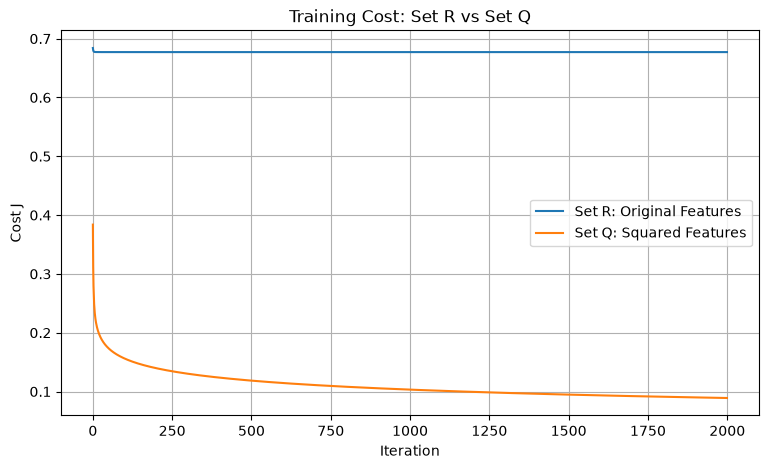

In [30]:

# Compare Set R and Set Q training costs

plt.figure(figsize=(9, 5))

plt.plot(costs_r, label="Set R: Original Features")
plt.plot(costs_q, label="Set Q: Squared Features")

plt.xlabel("Iteration")
plt.ylabel("Cost J")
plt.title("Training Cost: Set R vs Set Q")
plt.legend()
plt.grid(True)

Path("results").mkdir(exist_ok=True)
plt.savefig("results/set_r_vs_set_q_cost.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [33]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -

In [34]:
# **Task 4.1: Import the SVM classifier**

from sklearn.svm import SVC
import pandas as pd

print("SVM imported successfully!")

SVM imported successfully!


In [35]:

# Compare linear SVM models

C_values = [0.1, 1, 10, 100]
linear_results = []
linear_models = {}

for C in C_values:
    model = SVC(kernel="linear", C=C)
    model.fit(X_train_scaled, y_train)

    val_predictions = model.predict(X_val_scaled)
    val_accuracy = accuracy(y_val, val_predictions)
    support_vectors = model.n_support_.sum()

    linear_models[C] = model

    linear_results.append({
        "Kernel": "Linear",
        "C": C,
        "Gamma": "-",
        "Validation Accuracy (%)": round(val_accuracy, 2),
        "Support Vectors": support_vectors
    })

linear_table = pd.DataFrame(linear_results)
print(linear_table.to_string(index=False))


Kernel     C Gamma  Validation Accuracy (%)  Support Vectors
Linear   0.1     -                    72.58             5849
Linear   1.0     -                    72.58             5843
Linear  10.0     -                    72.58             5835
Linear 100.0     -                    72.62             5835


In [36]:

# Copare RBF SVM model

C_values = [0.1, 1, 10, 100]
gamma_values = [0.1, 1]

rbf_results = []
rbf_models = {}

for C in C_values:
    for gamma in gamma_values:
        model = SVC(kernel="rbf", C=C, gamma=gamma)
        model.fit(X_train_scaled, y_train)

        val_predictions = model.predict(X_val_scaled)
        val_accuracy = accuracy(y_val, val_predictions)
        support_vectors = model.n_support_.sum()

        rbf_models[(C, gamma)] = model

        rbf_results.append({
            "Kernel": "RBF",
            "C": C,
            "Gamma": gamma,
            "Validation Accuracy (%)": round(val_accuracy, 2),
            "Support Vectors": support_vectors
        })

rbf_table = pd.DataFrame(rbf_results)
print(rbf_table.to_string(index=False))


Kernel     C  Gamma  Validation Accuracy (%)  Support Vectors
   RBF   0.1    0.1                    95.00             1347
   RBF   0.1    1.0                    98.04              848
   RBF   1.0    0.1                    97.50              723
   RBF   1.0    1.0                    99.17              482
   RBF  10.0    0.1                    99.21              381
   RBF  10.0    1.0                    99.62              342
   RBF 100.0    0.1                    99.54              174
   RBF 100.0    1.0                    99.67              266


In [37]:

#Select and save the best SVM model

import joblib
from pathlib import Path

# Select the best models from validation results
best_linear_model = linear_models[100]
best_rbf_model = rbf_models[(100, 1)]

# Create the results folder if it does not exist
Path("results").mkdir(exist_ok=True)

# Save both models
joblib.dump(best_linear_model, "results/best_linear_svm.joblib")
joblib.dump(best_rbf_model, "results/best_rbf_svm.joblib")

print("Best linear SVM: C = 100")
print("Best RBF SVM: C = 100, gamma = 1")
print("Both models saved successfully.")


Best linear SVM: C = 100
Best RBF SVM: C = 100, gamma = 1
Both models saved successfully.


In [38]:

# Combine all SVM validation results

svm_table = pd.concat(
    [linear_table, rbf_table],
    ignore_index=True
)

print(svm_table.to_string(index=False))

# Save the table
Path("results").mkdir(exist_ok=True)
svm_table.to_csv("results/svm_validation_results.csv", index=False)

print("\nSVM validation table saved.")


Kernel     C Gamma  Validation Accuracy (%)  Support Vectors
Linear   0.1     -                    72.58             5849
Linear   1.0     -                    72.58             5843
Linear  10.0     -                    72.58             5835
Linear 100.0     -                    72.62             5835
   RBF   0.1   0.1                    95.00             1347
   RBF   0.1   1.0                    98.04              848
   RBF   1.0   0.1                    97.50              723
   RBF   1.0   1.0                    99.17              482
   RBF  10.0   0.1                    99.21              381
   RBF  10.0   1.0                    99.62              342
   RBF 100.0   0.1                    99.54              174
   RBF 100.0   1.0                    99.67              266

SVM validation table saved.


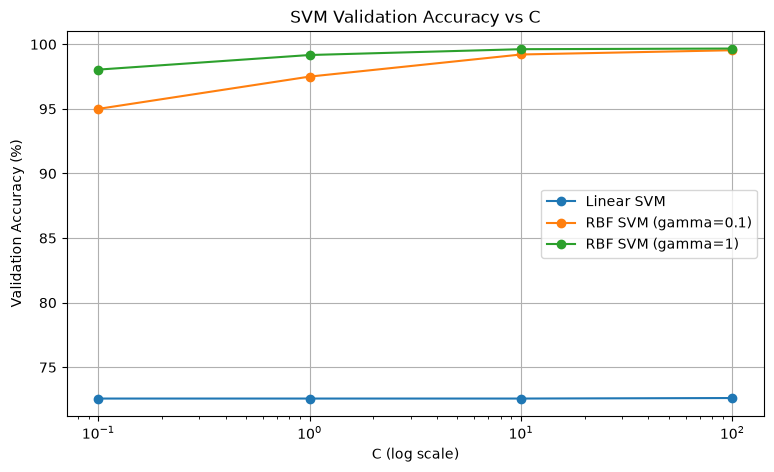

In [39]:

#Plot SVM validation accuracy against C

plt.figure(figsize=(9, 5))

# Linear SVM
plt.plot(
    linear_table["C"],
    linear_table["Validation Accuracy (%)"],
    marker="o",
    label="Linear SVM"
)

# RBF SVM for each gamma value
for gamma in gamma_values:
    subset = rbf_table[rbf_table["Gamma"] == gamma]

    plt.plot(
        subset["C"],
        subset["Validation Accuracy (%)"],
        marker="o",
        label=f"RBF SVM (gamma={gamma})"
    )

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Validation Accuracy (%)")
plt.title("SVM Validation Accuracy vs C")
plt.legend()
plt.grid(True)

plt.savefig(
    "results/svm_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [40]:

# Create confusion matrix

def confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    false_alarms = np.sum((y_true == 0) & (y_pred == 1))
    missed_faults = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([
        [tn, false_alarms],
        [missed_faults, tp]
    ])

print("Confusion matrix function created.")


Confusion matrix function created.


In [41]:

# Evaluate the four final models on test data

# Get predictions from all four models
test_pred_r = predict(X_test_lr, theta_r)
test_pred_q = predict(X_test_q_lr, theta_q)

test_pred_linear = best_linear_model.predict(X_test_scaled)
test_pred_rbf = best_rbf_model.predict(X_test_scaled)

# Store each model's predictions
test_predictions = {
    "Logistic Regression - Set R": test_pred_r,
    "Logistic Regression - Set Q": test_pred_q,
    "Linear SVM": test_pred_linear,
    "RBF SVM": test_pred_rbf
}

# Calculate accuracy and confusion matrix for each model
for name, predictions in test_predictions.items():
    cm = confusion_matrix(y_test, predictions)
    test_accuracy = accuracy(y_test, predictions)

    print("\n", name)
    print("Test accuracy:", round(test_accuracy, 2), "%")
    print("Confusion matrix:")
    print(cm)
    print("Missed faults:", cm[1, 0])
    print("False alarms:", cm[0, 1])



 Logistic Regression - Set R
Test accuracy: 72.64 %
Confusion matrix:
[[1305    0]
 [ 657  439]]
Missed faults: 657
False alarms: 0

 Logistic Regression - Set Q
Test accuracy: 97.0 %
Confusion matrix:
[[1305    0]
 [  72 1024]]
Missed faults: 72
False alarms: 0

 Linear SVM
Test accuracy: 73.64 %
Confusion matrix:
[[1305    0]
 [ 633  463]]
Missed faults: 633
False alarms: 0

 RBF SVM
Test accuracy: 99.58 %
Confusion matrix:
[[1301    4]
 [   6 1090]]
Missed faults: 6
False alarms: 4


In [42]:

#  Create and save the final test results table

test_results = []

for name, predictions in test_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    test_results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy(y_test, predictions), 2),
        "TN": cm[0, 0],
        "False Alarms": cm[0, 1],
        "Missed Faults": cm[1, 0],
        "TP": cm[1, 1]
    })

test_table = pd.DataFrame(test_results)

print(test_table.to_string(index=False))

test_table.to_csv("results/test_results.csv", index=False)
print("\nTest results saved to results/test_results.csv")


                      Model  Accuracy (%)   TN  False Alarms  Missed Faults   TP
Logistic Regression - Set R         72.64 1305             0            657  439
Logistic Regression - Set Q         97.00 1305             0             72 1024
                 Linear SVM         73.64 1305             0            633  463
                    RBF SVM         99.58 1301             4              6 1090

Test results saved to results/test_results.csv


In [43]:

#  Display Set Q model weights

weight_names = [
    "Intercept",
    "Ia", "Ib", "Ic",
    "Va", "Vb", "Vc",
    "Ia_squared", "Ib_squared", "Ic_squared",
    "Va_squared", "Vb_squared", "Vc_squared"
]

for name, weight in zip(weight_names, theta_q):
    print(f"{name:15s}: {weight:.6f}")


Intercept      : 9.066820
Ia             : 1.123212
Ib             : -1.797760
Ic             : 0.046163
Va             : -0.290128
Vb             : 0.256012
Vc             : 0.023369
Ia_squared     : 6.347908
Ib_squared     : 2.604035
Ic_squared     : 4.449222
Va_squared     : -3.415185
Vb_squared     : -3.484825
Vc_squared     : -3.415960


In [7]:

# Section: Rebuild and Save Logistic Regression Set Q

import numpy as np
import pandas as pd
from pathlib import Path

# Find the dataset without changing your existing files
possible_paths = [
    Path.cwd() / "data" / "detect_dataset.csv",
    Path.cwd() / "detect_dataset.csv",
    Path.cwd().parent / "data" / "detect_dataset.csv"
]

dataset_path = next(
    (p for p in possible_paths if p.exists()), None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Cannot find detect_dataset.csv. Check its location in your project."
    )

# Load the dataset
df = pd.read_csv(dataset_path)
df = df.rename(columns={"Output (S)": "fault"})

features = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]
X = df[features].to_numpy(dtype=float)
y = df["fault"].to_numpy(dtype=int)

# Recreate the assignment's 60/20/20 split
rng = np.random.default_rng(42)
indices = rng.permutation(len(df))

n_train = int(0.60 * len(df))
n_val = int(0.20 * len(df))

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

X_train_raw = X[train_idx]
y_train = y[train_idx]

# Create Set Q: original features plus squared features
X_train_q = np.c_[X_train_raw, X_train_raw ** 2]

# Standardize using training data only
q_mean = X_train_q.mean(axis=0)
q_std = X_train_q.std(axis=0)
q_std[q_std == 0] = 1

X_train_q_scaled = (X_train_q - q_mean) / q_std

# Add the intercept column
X_train_q_lr = np.c_[
    np.ones(len(X_train_q_scaled)),
    X_train_q_scaled
]

# Define logistic regression from scratch
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def fit_logistic(X, y, alpha, n_iters):
    theta = np.zeros(X.shape[1])
    costs = []

    for _ in range(n_iters):
        probabilities = sigmoid(X @ theta)
        gradient = X.T @ (y - probabilities) / len(y)
        theta += alpha * gradient

        p = np.clip(sigmoid(X @ theta), 1e-12, 1 - 1e-12)
        cost = -np.mean(
            y * np.log(p) + (1 - y) * np.log(1 - p)
        )
        costs.append(cost)

    return theta, costs

# Train Set Q
theta_q, costs_q = fit_logistic(
    X_train_q_lr, y_train, 1, 2000
)

# Save parameters in the main results folder
results_folder = Path.cwd() / "results"
results_folder.mkdir(exist_ok=True)

np.savez(
    results_folder / "logistic_set_q_params.npz",
    theta_q=theta_q,
    q_mean=q_mean,
    q_std=q_std
)

print("Set Q training completed!")
print("Training rows:", len(y_train))
print("Parameter shape:", theta_q.shape)
print("Final training cost:", round(costs_q[-1], 6))
print("Saved parameters to:", results_folder / "logistic_set_q_params.npz")


Set Q training completed!
Training rows: 7200
Parameter shape: (13,)
Final training cost: 0.088989
Saved parameters to: e:\dowload\aml assgnment 2\results\logistic_set_q_params.npz
